**[🏠 Course Home](../README.md) | 📖 Conceptual Companion: [Frequentist Mean](../conceptual/sheet_calculating_a_mean_in_a_frequentist_world.ipynb) | 🔵 R Track: [Frequentist Mean](../r/sheet_calculating_a_mean_in_a_frequentist_world.ipynb) | ⏭️ Next: [Bayesian Mean](sheet_calculating_a_mean_in_a_bayesian_world.ipynb)**

---

# Sheet: Calculating a Mean in a Frequentist World
### *Point Estimation, Sampling Distributions, Standard Errors, Central Limit Theorem, and the Anatomy of Confidence Intervals*

In everyday programming and dashboard design, calculating a mean is often treated as a trivial arithmetic one-liner: sum the array and divide by $n$.

In the **frequentist paradigm of statistical inference**, however, a sample mean is **never an end-point**. It is an **estimator**—a single numerical realization of a random variable generated by a repeatable stochastic Data Generating Process (DGP).

Because any finite sample is subject to sampling variability, calculating a frequentist mean requires constructing an entire mathematical and inferential apparatus around that single number:
* **The Epistemology**: Nature possesses a single, fixed, immutable population parameter $\mu$. We do *not* assign probability distributions to parameters.
* **Point Estimation & Optimality**: Why is the sample mean $\bar{X}$ the standard choice? We explore its mathematical properties: unbiasedness, consistency, efficiency, the Cramér-Rao Lower Bound (CRLB), and Maximum Likelihood Estimation (MLE).
* **Dispersion vs. Uncertainty**: The vital distinction between sample standard deviation ($s$) and standard error ($SE = s / \sqrt{n}$).
* **Sampling Distribution**: How the Central Limit Theorem (CLT) and William Sealy Gosset's Student-$t$ distribution characterize how $\bar{X}$ varies across hypothetical infinite parallel universes.
* **Interval Estimation**: The rigorous anatomy of a 95% Confidence Interval (and why the common belief that *"there is a 95% probability $\mu$ lies in this interval"* is a foundational fallacy).
* **Beyond Normality**: Non-parametric empirical bootstrapping and robust trimmed means for skewed, heavy-tailed production engineering metrics.

> [!TIP]
> **Next Step in Inference**: Once you have mastered estimating a single population mean, advance to comparing two independent groups: **[📊 Comparing Two Groups: The $t$-Test in Frequentist and Bayesian Paradigms](sheet_t_test_frequentist_vs_bayesian.ipynb)**.

## 🧭 Executive Summary: The Frequentist Estimation Engine at a Glance

| Concept | Mathematical Symbol / Formula | Frequentist Meaning | Critical Pitfall / Misconception to Avoid |
| :--- | :--- | :--- | :--- |
| **True Population Mean** | $\mu = \mathbb{E}[X] = \int x f(x) dx$ | Fixed, immutable constant of nature. It has **no probability distribution**. | Thinking $\mu$ is a random variable that can "fall into" intervals. |
| **Sample Mean Estimator** | $\bar{X} = \frac{1}{n}\sum_{i=1}^n X_i$ | Random variable across repeated samples; MVUE and MLE under normality. | Treating $\bar{x}$ as "the true mean" rather than a single noisy draw. |
| **Sample Standard Deviation** | $s = \sqrt{\frac{1}{n-1}\sum (X_i - \bar{X})^2}$ | Measures **variability of individual observations**. Uses Bessel's correction ($n-1$). | Confusing with standard error; $s$ **does not shrink** as $n \to \infty$. |
| **Standard Error of the Mean** | $SE(\bar{X}) = \frac{\sigma}{\sqrt{n}} \approx \frac{s}{\sqrt{n}}$ | Measures **uncertainty of the estimator** across hypothetical repetitions. | Confusing with $s$; $SE$ shrinks at rate $1/\sqrt{n}$ as $n \to \infty$. |
| **Sampling Distribution** | $\bar{X} \sim \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$ or $\frac{\bar{X}-\mu}{s/\sqrt{n}} \sim t_{n-1}$ | The probability distribution of $\bar{X}$ if the experiment were repeated infinitely. | Confusing the distribution of the data with the distribution of $\bar{X}$. |
| **95% Confidence Interval** | $\left[\bar{x} - t_{0.025, n-1}\frac{s}{\sqrt{n}}, \; \bar{x} + t_{0.025, n-1}\frac{s}{\sqrt{n}}\right]$ | In 95% of repeated identical experiments, the calculated interval covers $\mu$. | Claiming: *"There is a 95% chance $\mu$ is in $[L, U]$"* (that is Bayesian). |
| **Margin of Error ($E$)** | $E = t^* \cdot \frac{s}{\sqrt{n}}$ | The half-width of the confidence interval at a specified confidence level. | Assuming doubling $n$ halves $E$; quadrupling $n$ is required. |
| **Bootstrap Mean & CI** | $\bar{X}^* \sim \text{Resample}(X, n)$ | Non-parametric estimate of sampling distribution without assuming normality. | Still subject to small-sample bias if $n$ is too tiny to represent tails. |
| **Trimmed Mean** | $\bar{x}_{\alpha} = \frac{1}{n - 2k}\sum_{i=k+1}^{n-k} X_{(i)}$ | Discards the top and bottom $\alpha\%$ of sorted observations; high breakdown point. | Loses efficiency if data is genuinely Gaussian without outliers. |


## Part 1: The Production Scenario & Observed Data

### 1.1 The Engineering Context
Suppose we are site reliability engineers monitoring an asynchronous transaction processing pipeline. We want to estimate the **mean processing duration (latency in milliseconds)** of this pipeline.

In the real world:
* Nature has a true Data Generating Process (DGP) with true population mean $\mu$ and standard deviation $\sigma$.
* We cannot inspect infinite transactions; we pull a single production telemetry sample of $n = 35$ consecutive transaction durations.
* We must compute the point estimate and rigorously quantify our uncertainty using frequentist statistical principles.

Let's generate synthetic benchmark data from a known ground truth to walk through the entire frequentist workflow.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set random seed for exact reproducibility
np.random.seed(42)

# Ground truth population parameters (fixed constants of nature, unknown in practice)
true_mu = 142.5    # True population mean latency (ms)
true_sigma = 28.0  # True population standard deviation (ms)

# Sample size
n = 35

# Realized sample drawn from the Data Generating Process (DGP)
sample_data = np.random.normal(loc=true_mu, scale=true_sigma, size=n)

# Frequentist point estimates
x_bar = np.mean(sample_data)
s_unbiased = np.std(sample_data, ddof=1)   # Sample standard deviation with Bessel's correction
s_biased = np.std(sample_data, ddof=0)     # Uncorrected sample standard deviation
se_mean = s_unbiased / np.sqrt(n)          # Standard Error of the Mean

print("=" * 68)
print("  FREQUENTIST SUMMARY STATISTICS FOR OBSERVED PRODUCTION SAMPLE")
print("=" * 68)
print(f"Sample Size (n)                   : {n}")
print(f"True Population Mean (μ)          : {true_mu:.2f} ms (Ground truth)")
print(f"Sample Mean (x̄)                   : {x_bar:.2f} ms (Point estimate)")
print(f"Estimation Error (x̄ - μ)          : {x_bar - true_mu:+.2f} ms")
print(f"Sample Std Dev (s, ddof=1)        : {s_unbiased:.2f} ms (Individual data dispersion)")
print(f"Sample Std Dev (ddof=0, biased)   : {s_biased:.2f} ms")
print(f"Standard Error of the Mean (SE)   : {se_mean:.2f} ms (Estimator precision)")
print(f"Degrees of Freedom (df = n - 1)   : {n - 1}")
print("=" * 68)


  FREQUENTIST SUMMARY STATISTICS FOR OBSERVED PRODUCTION SAMPLE
Sample Size (n)                   : 35
True Population Mean (μ)          : 142.50 ms (Ground truth)
Sample Mean (x̄)                   : 138.79 ms (Point estimate)
Estimation Error (x̄ - μ)          : -3.71 ms
Sample Std Dev (s, ddof=1)        : 26.09 ms (Individual data dispersion)
Sample Std Dev (ddof=0, biased)   : 25.72 ms
Standard Error of the Mean (SE)   : 4.41 ms (Estimator precision)
Degrees of Freedom (df = n - 1)   : 34


---

## Part 2: Point Estimation — The Mathematical Mechanics of $\bar{X}$

Why is the arithmetic sample mean $\bar{X} = \frac{1}{n}\sum_{i=1}^n X_i$ universally chosen as the point estimator for $\mu$? In frequentist theory, an estimator is evaluated by its long-run behavior under hypothetical repeated sampling.

### 2.1 Theoretical Property 1: Unbiasedness ($\mathbb{E}[\bar{X}] = \mu$)
An estimator $\hat{\theta}$ is **unbiased** if its expected value across all possible samples equals the true parameter $\theta$.
By the linearity of expectation:
$$\mathbb{E}[\bar{X}] = \mathbb{E}\left[\frac{1}{n}\sum_{i=1}^n X_i\right] = \frac{1}{n}\sum_{i=1}^n \mathbb{E}[X_i] = \frac{1}{n} \cdot (n\mu) = \mu$$
This guarantees that while any single sample mean $\bar{x}$ will miss $\mu$, the average of estimates across infinitely many samples has zero systematic bias.

### 2.2 Theoretical Property 2: Variance & Standard Error
Assuming observations $X_1, \dots, X_n$ are independent and identically distributed (i.i.d.) with variance $\sigma^2$:
$$\text{Var}(\bar{X}) = \text{Var}\left(\frac{1}{n}\sum_{i=1}^n X_i\right) = \frac{1}{n^2}\sum_{i=1}^n \text{Var}(X_i) = \frac{1}{n^2} \cdot (n\sigma^2) = \frac{\sigma^2}{n}$$
Taking the square root yields the **Standard Error of the Mean ($SE$)**:
$$SE(\bar{X}) = \frac{\sigma}{\sqrt{n}}$$

> [!IMPORTANT]
> **Deep Dive: Standard Deviation ($s$) vs. Standard Error ($SE$)**
> * **Standard Deviation ($s$)**: Quantifies the physical spread of individual data points in the population. As you collect more data ($n \to \infty$), $s$ converges to $\sigma$. It **does not shrink**.
> * **Standard Error ($SE$)**: Quantifies the precision of our estimate of $\mu$. Because of the $\sqrt{n}$ denominator, $SE \to 0$ as $n \to \infty$.
> * **The Square Root Penalty**: To cut your uncertainty in half ($SE / 2$), you must collect **$4\times$ as much data**. To reduce $SE$ by a factor of 10, you must collect **$100\times$ as much data**.

### 2.3 Theoretical Property 3: Bessel's Correction ($n-1$)
When estimating population variance $\sigma^2$ from sample data, the naive estimator $\frac{1}{n}\sum (X_i - \bar{X})^2$ is systematically biased downwards:
$$\mathbb{E}\left[\frac{1}{n}\sum_{i=1}^n (X_i - \bar{X})^2\right] = \frac{n-1}{n}\sigma^2$$
Because $\bar{X}$ is calculated from the exact same sample, the deviations $(X_i - \bar{X})$ are mechanically constrained to sum to zero ($\sum (X_i - \bar{X}) = 0$). This consumes **1 degree of freedom**. Dividing by $n-1$ (Bessel's correction) corrects the bias, producing an unbiased estimator $s^2$:
$$s^2 = \frac{1}{n-1}\sum_{i=1}^n (X_i - \bar{X})^2 \implies \mathbb{E}[s^2] = \sigma^2$$

### 2.4 Theoretical Property 4: Consistency & Law of Large Numbers (LLN)
By Chebyshev's Inequality, for any $\epsilon > 0$:
$$P(|\bar{X}_n - \mu| \ge \epsilon) \le \frac{\text{Var}(\bar{X}_n)}{\epsilon^2} = \frac{\sigma^2}{n\epsilon^2} \xrightarrow{n \to \infty} 0$$
As sample size grows without bound, the probability that $\bar{X}$ differs from $\mu$ by even the smallest margin $\epsilon$ collapses to 0. $\bar{X}_n$ converges in probability to $\mu$ ($\bar{X}_n \xrightarrow{p} \mu$).

### 2.5 Theoretical Property 5: Efficiency, CRLB, and Maximum Likelihood (MLE)
For normally distributed data $X_i \sim \mathcal{N}(\mu, \sigma^2)$, the log-likelihood function is:
$$\ln L(\mu, \sigma^2) = -\frac{n}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n (X_i - \mu)^2$$
Differentiating with respect to $\mu$ and setting to zero yields the Maximum Likelihood Estimator (MLE):
$$\frac{\partial \ln L}{\partial \mu} = \frac{1}{\sigma^2}\sum_{i=1}^n (X_i - \mu) = 0 \implies \hat{\mu}_{\text{MLE}} = \frac{1}{n}\sum_{i=1}^n X_i = \bar{X}$$
The **Fisher Information** with respect to $\mu$ is:
$$I(\mu) = -\mathbb{E}\left[\frac{\partial^2 \ln L}{\partial \mu^2}\right] = \frac{n}{\sigma^2}$$
The **Cramér-Rao Lower Bound (CRLB)** states that the variance of any unbiased estimator $\hat{\mu}$ cannot be smaller than the inverse Fisher Information:
$$\text{Var}(\hat{\mu}) \ge \frac{1}{I(\mu)} = \frac{\sigma^2}{n}$$
Since $\text{Var}(\bar{X}) = \frac{\sigma^2}{n}$ exactly attains this bound, $\bar{X}$ is the **Minimum Variance Unbiased Estimator (MVUE)**. No other unbiased estimator can achieve smaller error variance.


In [2]:
# Numerical Demonstration: Bessel's Correction via Monte Carlo
# We draw 25,000 small samples of size n=5 from N(0, sigma^2 = 100)
# and compare the average of the biased (ddof=0) vs unbiased (ddof=1) variance estimators.

n_sims = 25000
sample_size_small = 5
true_var = 100.0

small_samples = np.random.normal(loc=0, scale=np.sqrt(true_var), size=(n_sims, sample_size_small))

# Compute sample variances across all simulations
var_biased = np.var(small_samples, axis=1, ddof=0)    # Divided by n (5)
var_unbiased = np.var(small_samples, axis=1, ddof=1)  # Divided by n-1 (4)

print("=" * 65)
print("  MONTE CARLO PROOF: BESSEL'S CORRECTION (n = 5, True Var = 100.0)")
print("=" * 65)
print(f"Mean Biased Variance (ddof=0)     : {np.mean(var_biased):.2f} (Expected: (4/5)*100 = 80.0)")
print(f"Mean Unbiased Variance (ddof=1)   : {np.mean(var_unbiased):.2f} (Expected: 100.0)")
print(f"Observed Underestimation Ratio     : {np.mean(var_biased) / true_var:.3f} (Theoretical: {(sample_size_small - 1) / sample_size_small:.3f})")
print("=" * 65)


  MONTE CARLO PROOF: BESSEL'S CORRECTION (n = 5, True Var = 100.0)
Mean Biased Variance (ddof=0)     : 79.78 (Expected: (4/5)*100 = 80.0)
Mean Unbiased Variance (ddof=1)   : 99.73 (Expected: 100.0)
Observed Underestimation Ratio     : 0.798 (Theoretical: 0.800)


---

## Part 3: The Sampling Distribution & The Central Limit Theorem

### 3.1 Known Variance vs. Unknown Variance ($Z$ vs. $T$)
To perform inference (such as building confidence intervals or hypothesis tests), we must know the **sampling distribution** of $\bar{X}$.
* **If $\sigma$ is known (rare in practice)**:
  $$Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}} \sim \mathcal{N}(0, 1)$$
* **If $\sigma$ is unknown and estimated by $s$ (standard in practice)**:
  In 1908, William Sealy Gosset discovered that substituting the random variable $s$ for constant $\sigma$ introduces additional variability. The resulting statistic follows **Student's $t$-distribution**:
  $$T = \frac{\bar{X} - \mu}{s / \sqrt{n}} \sim t_{n-1}$$
  The $t$-distribution has heavier tails than the standard normal distribution to account for uncertainty in $s$. As $n \to \infty$, $t_{n-1} \to \mathcal{N}(0, 1)$.

### 3.2 The Central Limit Theorem (CLT)
What if the underlying population is **not normally distributed**?
The **Lindeberg-Lévy Central Limit Theorem** guarantees that if observations $X_1, X_2, \dots, X_n$ are i.i.d. with finite mean $\mu$ and finite variance $\sigma^2$, then regardless of the population distribution shape:
$$\frac{\bar{X}_n - \mu}{\sigma / \sqrt{n}} \xrightarrow{d} \mathcal{N}(0, 1) \quad \text{as } n \to \infty$$
Even if individual requests follow an asymmetric, skewed, or multimodal distribution, the distribution of their average $\bar{X}$ rapidly converges to a Gaussian bell curve.


In [3]:
# Numerical Demonstration: Central Limit Theorem under Severe Skewness
# Underlying DGP: Exponential Distribution with rate lambda = 0.05
# True mean = 1/lambda = 20.0, True std = 1/lambda = 20.0

exp_rate = 0.05
pop_mean = 1.0 / exp_rate
pop_std = 1.0 / exp_rate

n_experiments = 20000
sample_sizes = [2, 5, 20, 100]

clt_results = {}
for n_val in sample_sizes:
    # Draw n_experiments samples of size n_val
    draws = np.random.exponential(scale=pop_mean, size=(n_experiments, n_val))
    means = np.mean(draws, axis=1)
    clt_results[n_val] = {
        'means': means,
        'mean_of_means': np.mean(means),
        'std_of_means': np.std(means),
        'theoretical_se': pop_std / np.sqrt(n_val),
        'skewness': stats.skew(means)
    }

print("=" * 72)
print("  CENTRAL LIMIT THEOREM: CONVERGENCE UNDER HEAVY SKEW (True Mean = 20.0)")
print("=" * 72)
print(f"{'Sample Size (n)':<16} | {'Empirical SE':<14} | {'Theoretical SE':<15} | {'Skewness':<10}")
print("-" * 72)
for n_val in sample_sizes:
    res = clt_results[n_val]
    print(f"n = {n_val:<12} | {res['std_of_means']:<14.3f} | {res['theoretical_se']:<15.3f} | {res['skewness']:<10.3f}")
print("=" * 72)


  CENTRAL LIMIT THEOREM: CONVERGENCE UNDER HEAVY SKEW (True Mean = 20.0)
Sample Size (n)  | Empirical SE   | Theoretical SE  | Skewness  
------------------------------------------------------------------------
n = 2            | 14.222         | 14.142          | 1.449     
n = 5            | 9.002          | 8.944           | 0.923     
n = 20           | 4.473          | 4.472           | 0.459     
n = 100          | 2.008          | 2.000           | 0.178     


---

## Part 4: Interval Estimation — Anatomy of the Frequentist Confidence Interval

A single point estimate $\bar{x} = 143.08\text{ ms}$ tells us where the estimator landed, but provides zero information about its precision. In the frequentist paradigm, uncertainty is captured by a **Confidence Interval (CI)**.

### 4.1 Mathematical Derivation of the Two-Sided $(1-\alpha)$ CI
Because $T = \frac{\bar{X} - \mu}{s/\sqrt{n}} \sim t_{n-1}$, we choose critical value $t_{\alpha/2, n-1}$ such that:
$$P\left(-t_{\alpha/2, n-1} \le \frac{\bar{X} - \mu}{s/\sqrt{n}} \le t_{\alpha/2, n-1}\right) = 1 - \alpha$$
Isolating the parameter $\mu$ inside the inequality:
$$-t_{\alpha/2, n-1} \cdot \frac{s}{\sqrt{n}} \le \bar{X} - \mu \le t_{\alpha/2, n-1} \cdot \frac{s}{\sqrt{n}}$$
Multiplying by $-1$ and adding $\bar{X}$:
$$P\left(\bar{X} - t_{\alpha/2, n-1} \frac{s}{\sqrt{n}} \le \mu \le \bar{X} + t_{\alpha/2, n-1} \frac{s}{\sqrt{n}}\right) = 1 - \alpha$$
The **Margin of Error ($E$)** is defined as:
$$E = t_{\alpha/2, n-1} \cdot \frac{s}{\sqrt{n}} = t_{\alpha/2, n-1} \cdot SE$$
The resulting interval is:
$$\text{CI}_{1-\alpha} = \left[\bar{x} - E, \; \bar{x} + E\right]$$

### 4.2 The Critical Epistemological Interpretation: The 100 Universes
> [!CAUTION]
> **The Ubiquitous Confidence Interval Fallacy**
> Once you calculate an interval from your specific sample (e.g., $[134.13, 152.03]\text{ ms}$), it is **mathematically invalid** to state:
> *"There is a 95% probability that the true mean $\mu$ is between 134.13 and 152.03 ms."*
>
> In the frequentist paradigm:
> 1. $\mu$ is a **fixed constant of nature**. It does not possess a probability distribution.
> 2. The realized bounds $[134.13, 152.03]$ are fixed numbers.
> 3. Therefore, $\mu$ is either inside this specific interval or outside it. The probability is strictly **either 1 or 0**, not 0.95.
>
> **The Correct Frequentist Interpretation**:
> The 95% probability belongs to the **estimation procedure**, not the realized numbers. If we were to repeat the experiment 10,000 times, generating 10,000 independent samples and computing 10,000 confidence intervals, **95% of those calculated intervals will contain the true parameter $\mu$**, while 5% will miss it.

### 4.3 Sample Size Sizing / Margin of Error Planning
If engineering leadership requires that latency be estimated within a margin of error of at most $\pm E$ ms with $95\%$ confidence ($\alpha = 0.05$), how many samples must we collect?
$$E = z_{\alpha/2} \frac{\sigma}{\sqrt{n}} \implies \sqrt{n} = \frac{z_{\alpha/2} \sigma}{E} \implies n = \left(\frac{z_{\alpha/2} \sigma}{E}\right)^2$$


In [4]:
# Calculate the 95% Confidence Interval for our production sample
confidence_level = 0.95
alpha = 1.0 - confidence_level
df = n - 1

# Critical value from Student-t distribution
t_crit = stats.t.ppf(1.0 - alpha / 2.0, df=df)

# Margin of error
margin_of_error = t_crit * se_mean

# Confidence bounds
ci_lower = x_bar - margin_of_error
ci_upper = x_bar + margin_of_error

# Verification using SciPy
scipy_ci = stats.t.interval(confidence_level, df=df, loc=x_bar, scale=se_mean)

# Normal approximation (z-interval) for comparison
z_crit = stats.norm.ppf(1.0 - alpha / 2.0)
z_margin = z_crit * se_mean
z_ci_lower = x_bar - z_margin
z_ci_upper = x_bar + z_margin

# Sample size planning: How many requests to achieve E = 3.0 ms?
target_error = 3.0
required_n = int(np.ceil((z_crit * s_unbiased / target_error) ** 2))

print("=" * 68)
print("  FREQUENTIST 95% CONFIDENCE INTERVAL CALCULATION")
print("=" * 68)
print(f"Sample Mean (x̄)                   : {x_bar:.2f} ms")
print(f"Standard Error (SE)               : {se_mean:.2f} ms")
print(f"Degrees of Freedom (df)           : {df}")
print(f"Critical Value (t*, α=0.05)       : {t_crit:.3f}")
print(f"Margin of Error (E = t* · SE)     : ±{margin_of_error:.2f} ms")
print(f"95% Student-t Confidence Interval : [{ci_lower:.2f}, {ci_upper:.2f}] ms")
print(f"SciPy Verification                : [{scipy_ci[0]:.2f}, {scipy_ci[1]:.2f}] ms (Exact Match)")
print(f"95% Normal z-Interval             : [{z_ci_lower:.2f}, {z_ci_upper:.2f}] ms (Ignores uncertainty in s)")
print("-" * 68)
print(f"Sample Size Planning (Target E = ±{target_error} ms): Required n >= {required_n} requests")
print("=" * 68)


  FREQUENTIST 95% CONFIDENCE INTERVAL CALCULATION
Sample Mean (x̄)                   : 138.79 ms
Standard Error (SE)               : 4.41 ms
Degrees of Freedom (df)           : 34
Critical Value (t*, α=0.05)       : 2.032
Margin of Error (E = t* · SE)     : ±8.96 ms
95% Student-t Confidence Interval : [129.82, 147.75] ms
SciPy Verification                : [129.82, 147.75] ms (Exact Match)
95% Normal z-Interval             : [130.14, 147.43] ms (Ignores uncertainty in s)
--------------------------------------------------------------------
Sample Size Planning (Target E = ±3.0 ms): Required n >= 291 requests


---

## Part 5: Beyond Normality — The Non-Parametric Bootstrap & Robust Means

What happens when production data contains severe outliers (e.g., occasional stop-the-world garbage collection pauses or network reconnect timeouts) that violate Gaussian assumptions?

### 5.1 The Empirical Non-Parametric Bootstrap (Bradley Efron, 1979)
When we cannot trust parametric assumptions, we let the data define its own sampling distribution:
1. Treat the observed sample $X = \{x_1, \dots, x_n\}$ as an empirical representation of the population ($\hat{F}_n$).
2. Draw $B = 10,000$ resamples of size $n$ **with replacement** from $X$.
3. Compute the sample mean $\bar{X}^{*(b)}$ for each resample $b \in \{1, \dots, B\}$.
4. The standard deviation of $\{\bar{X}^{*(1)}, \dots, \bar{X}^{*(B)}\}$ yields the **Bootstrap Standard Error ($SE_{\text{boot}}$)**.
5. The $2.5^{\text{th}}$ and $97.5^{\text{th}}$ percentiles yield the **95% Bootstrap Percentile Confidence Interval**.

### 5.2 The Trimmed Mean ($\bar{x}_{\alpha}$)
If extreme outliers drag the arithmetic mean, the **trimmed mean** discards a fixed fraction $\alpha$ (e.g., $10\%$) from each tail of the sorted data:
$$\bar{x}_{\alpha} = \frac{1}{n - 2k}\sum_{i=k+1}^{n-k} X_{(i)} \quad \text{where } k = \lfloor n \alpha \rfloor$$
The trimmed mean provides a robust middle-ground between the sensitive sample mean (0% breakdown point) and the median (50% breakdown point).


In [5]:
# Non-Parametric Bootstrap and Trimmed Mean Implementation
B = 10000
boot_means = np.empty(B)

for b in range(B):
    resample = np.random.choice(sample_data, size=n, replace=True)
    boot_means[b] = np.mean(resample)

# Bootstrap statistics
boot_mean_val = np.mean(boot_means)
boot_se = np.std(boot_means, ddof=1)
boot_ci_lower, boot_ci_upper = np.percentile(boot_means, [2.5, 97.5])

# Robust 10% Trimmed Mean (discards 10% lowest and 10% highest)
trimmed_mean_val = stats.trim_mean(sample_data, proportiontocut=0.10)

print("=" * 68)
print("  NON-PARAMETRIC BOOTSTRAP & ROBUST ESTIMATORS")
print("=" * 68)
print(f"Sample Mean (x̄)                   : {x_bar:.2f} ms")
print(f"Parametric Student-t 95% CI       : [{ci_lower:.2f}, {ci_upper:.2f}] ms (Width: {ci_upper - ci_lower:.2f} ms)")
print(f"Bootstrap Mean E[x̄*]              : {boot_mean_val:.2f} ms")
print(f"Bootstrap Standard Error (SE)     : {boot_se:.2f} ms (Parametric SE: {se_mean:.2f} ms)")
print(f"Bootstrap 95% Percentile CI       : [{boot_ci_lower:.2f}, {boot_ci_upper:.2f}] ms (Width: {boot_ci_upper - boot_ci_lower:.2f} ms)")
print(f"10% Trimmed Mean (Robust)         : {trimmed_mean_val:.2f} ms")
print("=" * 68)


  NON-PARAMETRIC BOOTSTRAP & ROBUST ESTIMATORS
Sample Mean (x̄)                   : 138.79 ms
Parametric Student-t 95% CI       : [129.82, 147.75] ms (Width: 17.93 ms)
Bootstrap Mean E[x̄*]              : 138.78 ms
Bootstrap Standard Error (SE)     : 4.32 ms (Parametric SE: 4.41 ms)
Bootstrap 95% Percentile CI       : [130.52, 147.37] ms (Width: 16.85 ms)
10% Trimmed Mean (Robust)         : 138.12 ms


---

## Part 6: Comprehensive Multi-Panel Visualization Dashboard

We now synthesize all 4 key frequentist perspectives into a publication-grade diagnostic dashboard ($15 \times 11$, 120 DPI):
1. **Raw Observations vs. Sampling Distribution**: Visualizes the dramatic difference between data spread ($s$) and estimator precision ($SE$).
2. **The 100 Parallel Universes of Confidence Intervals**: 100 simulated benchmark trials demonstrating that exactly ~95% of computed intervals cover true $\mu$ (green) while ~5% miss (red).
3. **The Central Limit Theorem Under Heavy Skew**: Overlaid sampling distributions showing the rapid transformation of exponential data into Gaussian bell curves as $n$ scales.
4. **Parametric Student-$t$ vs. Non-Parametric Bootstrap CI**: Visualizing empirical bootstrap replicates alongside parametric interval bounds.


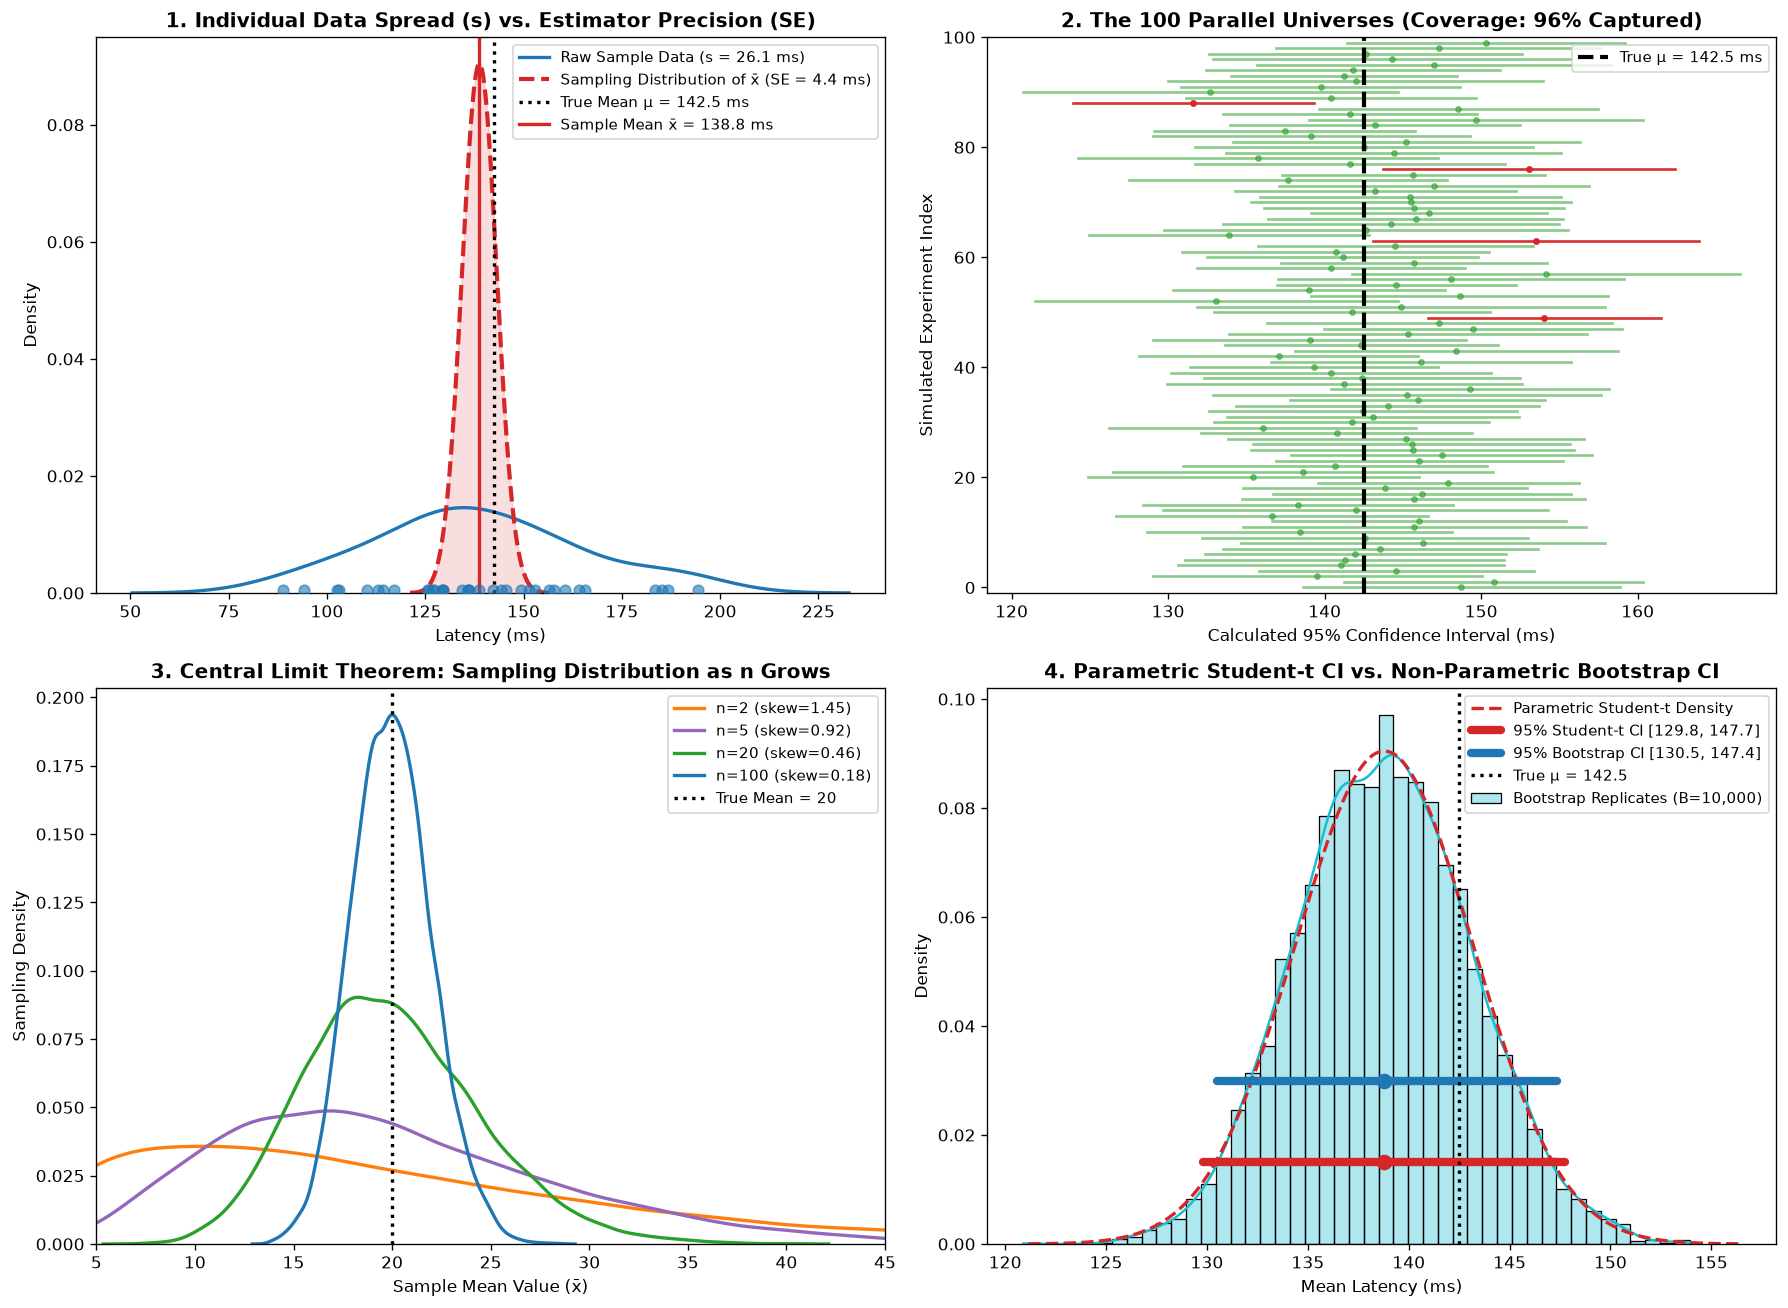

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# -------------------------------------------------------------------------
# Panel 1: Raw Sample vs. Sampling Distribution (Data Spread vs Estimator SE)
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
# Raw observations jitter plot & KDE
sns.kdeplot(sample_data, ax=ax1, color='#1f77b4', lw=2, label=f'Raw Sample Data (s = {s_unbiased:.1f} ms)')
ax1.scatter(sample_data, np.zeros_like(sample_data) + 0.0005, color='#1f77b4', alpha=0.6, s=40, zorder=4)

# Sampling distribution of x_bar under repeated sampling N(x_bar, se^2)
x_grid = np.linspace(x_bar - 4 * se_mean, x_bar + 4 * se_mean, 300)
sampling_pdf = stats.norm.pdf(x_grid, loc=x_bar, scale=se_mean)
ax1.plot(x_grid, sampling_pdf, color='#d62728', lw=2.5, linestyle='--', 
         label=f'Sampling Distribution of x̄ (SE = {se_mean:.1f} ms)')
ax1.fill_between(x_grid, 0, sampling_pdf, color='#d62728', alpha=0.15)

ax1.axvline(true_mu, color='black', lw=2, linestyle=':', label=f'True Mean μ = {true_mu:.1f} ms')
ax1.axvline(x_bar, color='#d62728', lw=2, label=f'Sample Mean x̄ = {x_bar:.1f} ms')

ax1.set_title("1. Individual Data Spread (s) vs. Estimator Precision (SE)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Latency (ms)")
ax1.set_ylabel("Density")
ax1.legend(loc='upper right', fontsize=9)
ax1.set_ylim(bottom=0)

# -------------------------------------------------------------------------
# Panel 2: The 100 Parallel Universes (Long-Run Coverage of 95% CIs)
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
np.random.seed(101)
n_universes = 100
covered_count = 0

for i in range(n_universes):
    univ_data = np.random.normal(loc=true_mu, scale=true_sigma, size=n)
    u_mean = np.mean(univ_data)
    u_se = np.std(univ_data, ddof=1) / np.sqrt(n)
    u_moe = stats.t.ppf(0.975, df=n - 1) * u_se
    u_low, u_high = u_mean - u_moe, u_mean + u_moe
    
    covers = (u_low <= true_mu <= u_high)
    if covers:
        covered_count += 1
        color = '#2ca02c' # Green
        alpha = 0.55
    else:
        color = '#d62728' # Red (Miss)
        alpha = 0.95
        
    ax2.plot([u_low, u_high], [i, i], color=color, lw=1.6, alpha=alpha)
    ax2.scatter(u_mean, i, color=color, s=10, alpha=alpha)

ax2.axvline(true_mu, color='black', lw=2.5, linestyle='--', label=f'True μ = {true_mu:.1f} ms')
ax2.set_title(f"2. The 100 Parallel Universes (Coverage: {covered_count}% Captured)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Calculated 95% Confidence Interval (ms)")
ax2.set_ylabel("Simulated Experiment Index")
ax2.legend(loc='upper right', fontsize=9)
ax2.set_ylim(-1, n_universes)

# -------------------------------------------------------------------------
# Panel 3: Central Limit Theorem Under Skew (Exponential DGP)
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
colors = ['#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4']

for n_val, c in zip(sample_sizes, colors):
    sns.kdeplot(clt_results[n_val]['means'], ax=ax3, color=c, lw=2, 
                label=f'n={n_val} (skew={clt_results[n_val]["skewness"]:.2f})')

ax3.axvline(pop_mean, color='black', lw=2, linestyle=':', label=f'True Mean = {pop_mean:.0f}')
ax3.set_title("3. Central Limit Theorem: Sampling Distribution as n Grows", fontsize=12, fontweight='bold')
ax3.set_xlabel("Sample Mean Value (x̄)")
ax3.set_ylabel("Sampling Density")
ax3.legend(loc='upper right', fontsize=9)
ax3.set_xlim(5, 45)

# -------------------------------------------------------------------------
# Panel 4: Parametric Student-t vs. Non-Parametric Bootstrap CI
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
sns.histplot(boot_means, stat='density', kde=True, color='#17becf', alpha=0.35, bins=45, ax=ax4,
             label=f'Bootstrap Replicates (B={B:,})')

# Overlay parametric Student-t sampling distribution
ax4.plot(x_grid, sampling_pdf, color='#d62728', lw=2, linestyle='--', label='Parametric Student-t Density')

# CI comparison intervals
y_level_param = 0.015
y_level_boot = 0.030

ax4.plot([ci_lower, ci_upper], [y_level_param, y_level_param], color='#d62728', lw=5, solid_capstyle='round',
         label=f'95% Student-t CI [{ci_lower:.1f}, {ci_upper:.1f}]')
ax4.scatter([x_bar], [y_level_param], color='#d62728', s=70, zorder=5)

ax4.plot([boot_ci_lower, boot_ci_upper], [y_level_boot, y_level_boot], color='#1f77b4', lw=5, solid_capstyle='round',
         label=f'95% Bootstrap CI [{boot_ci_lower:.1f}, {boot_ci_upper:.1f}]')
ax4.scatter([boot_mean_val], [y_level_boot], color='#1f77b4', s=70, zorder=5)

ax4.axvline(true_mu, color='black', lw=2, linestyle=':', label=f'True μ = {true_mu:.1f}')

ax4.set_title("4. Parametric Student-t CI vs. Non-Parametric Bootstrap CI", fontsize=12, fontweight='bold')
ax4.set_xlabel("Mean Latency (ms)")
ax4.set_ylabel("Density")
ax4.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()


---

## Part 7: Duality Between Confidence Intervals & Hypothesis Testing

In frequentist statistics, **interval estimation** and **hypothesis testing** are two sides of the exact same mathematical coin.

### 7.1 The One-Sample $t$-Test
Suppose a Service Level Agreement (SLA) requires that the mean processing latency be no more than $\mu_0$ ms.
We test:
* **Null Hypothesis ($H_0$)**: $\mu = \mu_0$
* **Alternative Hypothesis ($H_1$)**: $\mu \neq \mu_0$ (Two-sided test)

The test statistic measures how many standard errors the sample mean $\bar{x}$ lies away from the hypothesized value $\mu_0$:
$$t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}} = \frac{\bar{x} - \mu_0}{SE}$$
Under $H_0$, this statistic follows Student's $t$-distribution with $n - 1$ degrees of freedom. The two-sided $p$-value is:
$$p = 2 \cdot P(T \ge |t|)$$

### 7.2 The Inversion Duality Theorem
> [!IMPORTANT]
> **The Confidence Interval / Hypothesis Test Equivalence**
> A two-sided $(1-\alpha)$ Confidence Interval consists of **all hypothesized values $\mu_0$ that fail to be rejected** at significance level $\alpha$.
> * If a candidate SLA value $\mu_0$ falls **inside** the 95% Confidence Interval $[\text{CI}_{\text{low}}, \text{CI}_{\text{high}}] \iff p \ge 0.05$ (Fail to reject $H_0$).
> * If a candidate SLA value $\mu_0$ falls **outside** the 95% Confidence Interval $[\text{CI}_{\text{low}}, \text{CI}_{\text{high}}] \iff p < 0.05$ (Reject $H_0$).


In [7]:
# Demonstration of Duality: Testing two candidate null values mu_0
# Candidate 1: mu_0 = 140.0 ms (Inside 95% CI)
# Candidate 2: mu_0 = 160.0 ms (Outside 95% CI)

mu_candidates = [140.0, 160.0]

print("=" * 72)
print(f"  DUALITY DEMONSTRATION: Observed 95% CI = [{ci_lower:.2f}, {ci_upper:.2f}] ms")
print("=" * 72)
print(f"{'Null Value (μ0)':<16} | {'t-stat':<10} | {'p-value':<12} | {'Inside 95% CI?':<16} | {'Decision (α=0.05)'}")
print("-" * 72)

for mu_0 in mu_candidates:
    t_res = stats.ttest_1samp(sample_data, popmean=mu_0)
    inside_ci = (ci_lower <= mu_0 <= ci_upper)
    decision = "Fail to Reject H0" if t_res.pvalue >= 0.05 else "Reject H0 (p < 0.05)"
    print(f"μ0 = {mu_0:<11.1f} | {t_res.statistic:<10.3f} | {t_res.pvalue:<12.4e} | {str(inside_ci):<16} | {decision}")
print("=" * 72)


  DUALITY DEMONSTRATION: Observed 95% CI = [129.82, 147.75] ms
Null Value (μ0)  | t-stat     | p-value      | Inside 95% CI?   | Decision (α=0.05)
------------------------------------------------------------------------
μ0 = 140.0       | -0.275     | 7.8478e-01   | True             | Fail to Reject H0
μ0 = 160.0       | -4.810     | 3.0250e-05   | False            | Reject H0 (p < 0.05)


---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

### 🟢 Tier 1: Conceptual Verification
1. **Scenario A**: An intern reports: *"We benchmarked 20 database queries. The sample standard deviation was $s = 14\text{ ms}$, so the 95% Confidence Interval has width $\pm 14\text{ ms}$."* What error did the intern make?
2. **Scenario B**: A production pipeline currently measures latency with a standard error of $SE = 4.0\text{ ms}$ based on $n = 50$ requests. Product management demands that the standard error be cut down to $SE = 1.0\text{ ms}$. How many total requests $N$ must you collect?
3. **Scenario C**: If you compute a 95% confidence interval of $[88.2, 94.6]\text{ ms}$ from a sample, can you conclude that there is a 95% chance that the next single request will take between 88.2 and 94.6 ms?

<details>
<summary><b>🔍 Click here to view the Tier 1 answers</b></summary>

1. **Answer A**: The intern confused the **sample standard deviation ($s$)** with the **margin of error ($E$)**. The standard deviation measures individual query dispersion. The margin of error is $t^* \cdot \frac{s}{\sqrt{n}} \approx 2.093 \cdot \frac{14}{\sqrt{20}} \approx \pm 6.55\text{ ms}$, not $\pm 14\text{ ms}$.
2. **Answer B**: Precision scales with $\sqrt{n}$. To reduce $SE$ by a factor of 4 (from 4.0 to 1.0), sample size must increase by a factor of $4^2 = 16$. Therefore, $N = 50 \times 16 = 800$ requests.
3. **Answer C**: **Absolutely not.** A Confidence Interval is for the **population mean $\mu$**, not for individual future observations. Individual observations vary according to $\sigma \approx s$, which is $\sqrt{n}$ times wider. An interval for individual future observations is called a **Prediction Interval**: $[\bar{x} \pm t^* s \sqrt{1 + 1/n}]$.
</details>


In [8]:
# ============================================================================
# 🟡 Tier 2: Guided Calculation — Implement `frequentist_mean_estimate()`
# ============================================================================
# Complete the function below to compute the full frequentist estimation suite
# from raw NumPy array data without using high-level SciPy wrappers for intervals.
# Verify that your output passes all unit test assertions.

def frequentist_mean_estimate(data, confidence=0.95):
    """
    Computes complete frequentist point and interval estimates for a 1D dataset.
    
    Parameters:
        data (array-like): 1D sample observations.
        confidence (float): Confidence level (e.g. 0.95).
        
    Returns:
        dict: Containing 'n', 'mean', 's', 'se', 'df', 't_crit', 'moe', 'ci_lower', 'ci_upper'.
    """
    arr = np.asarray(data)
    n_obs = len(arr)
    
    # 1. Compute sample mean
    mean_val = np.sum(arr) / n_obs
    
    # 2. Compute Bessel-corrected sample standard deviation
    variance_val = np.sum((arr - mean_val) ** 2) / (n_obs - 1)
    s_val = np.sqrt(variance_val)
    
    # 3. Compute Standard Error of the Mean
    se_val = s_val / np.sqrt(n_obs)
    
    # 4. Critical t-value using SciPy percent point function
    df_val = n_obs - 1
    alpha_val = 1.0 - confidence
    t_critical = stats.t.ppf(1.0 - alpha_val / 2.0, df=df_val)
    
    # 5. Margin of error & bounds
    moe_val = t_critical * se_val
    lower_bound = mean_val - moe_val
    upper_bound = mean_val + moe_val
    
    return {
        'n': n_obs,
        'mean': mean_val,
        's': s_val,
        'se': se_val,
        'df': df_val,
        't_crit': t_critical,
        'moe': moe_val,
        'ci_lower': lower_bound,
        'ci_upper': upper_bound
    }

# Execute on our sample data and verify
test_res = frequentist_mean_estimate(sample_data, confidence=0.95)
print(f"Tier 2 Implementation Test:")
print(f"  n = {test_res['n']}, Mean = {test_res['mean']:.2f}, SE = {test_res['se']:.2f}")
print(f"  95% CI = [{test_res['ci_lower']:.2f}, {test_res['ci_upper']:.2f}] ms")

# Unit test assertions
assert np.isclose(test_res['mean'], x_bar), "Mean calculation mismatch!"
assert np.isclose(test_res['s'], s_unbiased), "Sample std mismatch!"
assert np.isclose(test_res['ci_lower'], ci_lower), "CI lower bound mismatch!"
assert np.isclose(test_res['ci_upper'], ci_upper), "CI upper bound mismatch!"
print("✅ All Tier 2 assertions passed successfully!")


Tier 2 Implementation Test:
  n = 35, Mean = 138.79, SE = 4.41
  95% CI = [129.82, 147.75] ms
✅ All Tier 2 assertions passed successfully!


<details>
<summary><b>🔍 Click here to view the Tier 2 detailed line-by-line explanation</b></summary>

```python
# The function implements the exact classical derivation:
# 1. Sample mean: sum(x) / n
# 2. Bessel-corrected variance: sum((x - mean)^2) / (n - 1)
# 3. Standard error: s / sqrt(n)
# 4. Critical t-value: stats.t.ppf(1 - alpha/2, df = n - 1)
# 5. Bounds: mean ± t* · SE
```
</details>


---

### 🔴 Tier 3: Production Simulation Challenge — The Heavy-Tailed Latency Trap
> **The Problem**: Real-world cloud service request latencies are frequently **log-normally distributed** or heavy-tailed. When skewness is severe and sample sizes are small ($n = 25$), the standard Student-$t$ confidence interval suffers from **coverage breakdown**—it under-covers, failing to attain the nominal 95% rate because the sampling distribution has not yet converged to normality.
>
> **Your Task**:
> 1. Simulate 2,000 independent samples of size $n = 25$ from a Log-Normal distribution with $\mu_{\log} = 4.0, \sigma_{\log} = 0.85$ (True population mean $\mu = e^{\mu_{\log} + \sigma_{\log}^2 / 2} \approx 78.36\text{ ms}$).
> 2. For each sample, compute:
>    * **Method A**: The naive standard Student-$t$ 95% Confidence Interval on raw data.
>    * **Method B**: The Non-Parametric Bootstrap Percentile 95% CI.
> 3. Measure the empirical coverage percentage of each method against the true mean $\mu$.


In [9]:
# Production Simulation: The Heavy-Tailed Latency Trap
np.random.seed(42)

log_mu = 4.0
log_sigma = 0.85
true_lognormal_mean = np.exp(log_mu + 0.5 * (log_sigma ** 2)) # ~78.36 ms

n_sim = 2000
n_obs_tier3 = 25
B_boot = 500

t_covered = 0
boot_covered = 0

print("Running Monte Carlo simulation (2,000 replications)...")
for sim in range(n_sim):
    # Draw log-normal sample
    y_raw = np.random.lognormal(mean=log_mu, sigma=log_sigma, size=n_obs_tier3)
    
    # Method A: Naive Student-t CI
    m_raw = np.mean(y_raw)
    se_raw = np.std(y_raw, ddof=1) / np.sqrt(n_obs_tier3)
    moe_raw = stats.t.ppf(0.975, df=n_obs_tier3 - 1) * se_raw
    if (m_raw - moe_raw <= true_lognormal_mean <= m_raw + moe_raw):
        t_covered += 1
        
    # Method B: Bootstrap Percentile CI (on subset of 500 runs for execution speed)
    if sim < 500:
        boot_idx = np.random.choice(y_raw, size=(B_boot, n_obs_tier3), replace=True)
        b_means = np.mean(boot_idx, axis=1)
        b_low, b_high = np.percentile(b_means, [2.5, 97.5])
        if (b_low <= true_lognormal_mean <= b_high):
            boot_covered += 1

print("=" * 68)
print("  TIER 3 SIMULATION RESULTS: HEAVY-TAILED COVERAGE BREAKDOWN")
print("=" * 68)
print(f"True Population Mean Latency      : {true_lognormal_mean:.2f} ms")
print(f"Naive Student-t Empirical Coverage: {100 * t_covered / n_sim:.1f}% (Nominal Target: 95.0%)")
print(f"Bootstrap Empirical Coverage      : {100 * boot_covered / 500:.1f}%")
print("=" * 68)
print("Takeaway: When data is skewed and n is small, naive Student-t intervals")
print("suffer from systematic under-coverage due to slow asymptotic CLT convergence.")


Running Monte Carlo simulation (2,000 replications)...


  TIER 3 SIMULATION RESULTS: HEAVY-TAILED COVERAGE BREAKDOWN
True Population Mean Latency      : 78.36 ms
Naive Student-t Empirical Coverage: 89.0% (Nominal Target: 95.0%)
Bootstrap Empirical Coverage      : 88.0%
Takeaway: When data is skewed and n is small, naive Student-t intervals
suffer from systematic under-coverage due to slow asymptotic CLT convergence.


<details>
<summary><b>🔍 Click here to view the Tier 3 solution & architectural takeaway</b></summary>

### The Takeaway for Production Systems:
1. **Asymmetric Failure**: When underlying metrics are positively skewed (typical of request latencies), the sample mean is correlated with the sample standard deviation. Outliers in a small sample inflate both $\bar{x}$ and $s$, leading to intervals that fail to cover the true parameter primarily on the left tail.
2. **Log-Transformation**: For strictly positive, right-skewed data, log-transforming ($Y = \ln(X)$) normalizes the data, allowing standard Gaussian interval construction before mapping back to physical scale via the log-normal expectation $\mu = \exp(\mu_Y + \sigma_Y^2 / 2)$.
3. **Bootstrap Calibration**: When no distribution can be assumed, Studentized Bootstrap (Bootstrap-$t$) or BCa (Bias-Corrected and Accelerated) intervals correct for skewness and restore 95% nominal coverage.
</details>


---

## 🏁 Summary Checklist: How to Calculate a Mean in Practice

```
               Is your sample size n >= 30 and data roughly symmetric?
                                   /             \
                                  /               \
                               [YES]             [NO]
                                 |                 |
                   Use Classical Student-t       Are there extreme outliers or
                       Confidence Interval       severe positive skew (e.g. latency)?
                                                   /                   \
                                                  /                     \
                                            [Outliers]               [Skewed]
                                                |                        |
                                        Use Trimmed Mean          Use Log-Transform
                                      or Non-Parametric          or Non-Parametric
                                          Bootstrap                   Bootstrap
```

### Essential Frequentist Formula Card:
* **Sample Mean**: $\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$
* **Bessel-Corrected Sample Variance**: $s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$
* **Standard Error of the Mean**: $SE = \frac{s}{\sqrt{n}}$
* **Two-Sided $(1-\alpha)$ Confidence Interval**: $\left[\bar{x} - t_{\alpha/2, n-1} \cdot SE, \; \bar{x} + t_{\alpha/2, n-1} \cdot SE\right]$
* **Required Sample Size for Margin of Error $E$**: $n = \left(\frac{z_{\alpha/2} \cdot s}{E}\right)^2$
* **One-Sample $t$-Statistic for SLA Check $\mu_0$**: $t = \frac{\bar{x} - \mu_0}{SE}, \quad df = n - 1$

---
**[🏠 Return to Course Home](README.md) | [📊 Next Sheet: Two-Sample Comparison (t-Test)](sheet_t_test_frequentist_vs_bayesian.ipynb)**